Complete the exercises below For **Assignment #5**.

In this exercise, we are building a logistic regression classification model. We'll work with the [Pima Indians Diabetes Database](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database).  

Load the `tidymodels` library. 

In [1]:
# Load the tidymodels library.
library(tidymodels)

# Set a seed so the train/test split in the next cell is reproducible.
set.seed(123)

── Attaching packages ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──

✔ broom        1.0.9     ✔ recipes      1.3.1
✔ dials        1.4.2     ✔ rsample      1.3.1
✔ dplyr        1.1.4     ✔ tailor       0.1.0
✔ ggplot2      3.5.2     ✔ tidyr        1.3.1
✔ infer        1.0.9     ✔ tune         2.0.0
✔ modeldata    1.5.1     ✔ workflows    1.3.0
✔ parsnip      1.3.3     ✔ workflowsets 1.1.1
✔ purrr        1.1.0     ✔ yardstick    1.3.2

── Conflicts ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ purrr::discard() masks scales::discard()
✖ dplyr::filter()  masks stats::filter()
✖ dplyr::lag()     masks stats::lag()
✖ recipes::step()  masks stats::step()



The data is located in your homework directory in the `diabetes.csv` file. Read in the data by running the following cell. We are "splitting" the data into training and testing sets. We will evaluate our model's performance with the test set.

In [2]:
diabetes = readr::read_csv('diabetes.csv') |> mutate(Outcome = factor(Outcome))

split = initial_split(diabetes, strata = Outcome)

diabetes_train = training(split)
diabetes_test = testing(split)

Rows: 768 Columns: 9
── Column specification ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: ","
dbl (9): Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, D...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Glimpse the `diabetes_train` table.

In [3]:
glimpse(diabetes_train)

Rows: 576
Columns: 9
$ Pregnancies              <dbl> 1, 5, 10, 4, 1, 1, 13, 5, 5, 3, 10, 7, 7, 7, …
$ Glucose                  <dbl> 89, 116, 115, 110, 103, 97, 145, 117, 109, 88…
$ BloodPressure            <dbl> 66, 74, 0, 92, 30, 66, 82, 92, 75, 58, 78, 84…
$ SkinThickness            <dbl> 23, 0, 0, 0, 38, 15, 19, 0, 26, 11, 31, 0, 18…
$ Insulin                  <dbl> 94, 0, 0, 0, 83, 140, 110, 0, 0, 54, 0, 0, 0,…
$ BMI                      <dbl> 28.1, 25.6, 35.3, 37.6, 43.3, 23.2, 22.2, 34.…
$ DiabetesPedigreeFunction <dbl> 0.167, 0.201, 0.134, 0.191, 0.183, 0.487, 0.2…
$ Age                      <dbl> 21, 30, 29, 30, 33, 22, 57, 38, 60, 22, 45, 3…
$ Outcome                  <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …


❓ Which variable is suitable as the "outcome" in a logistic regression model?

**Answer:** The `Outcome` variable (0 = no diabetes, 1 = diabetes) is the outcome/response. 
It is binary and categorical, which is exactly what logistic regression predicts — the probability 
of being in the "1" (diabetes) class from the predictor variables.

In [4]:
# Outcome: 1 = diabetes, 0 = no diabetes
diabetes_train |> count(Outcome)

Outcome,n
<fct>,<int>
0,375
1,201


❓ Navigate to [Kaggle page](https://www.kaggle.com/datasets/mathchi/diabetes-data-set) for this dataset. Find descriptions for the `Glucose` and `BMI` columns. Add these descriptions to the [Markdown table](https://www.markdownguide.org/extended-syntax/#tables) below.

| Column name | Description |
| :---------- | :---------- |
| Glucose     | Plasma glucose concentration (mg/dL) measured 2 hours into an oral glucose tolerance test. Higher values generally indicate higher blood sugar. |
| BMI         | Body Mass Index — a measure of body fat calculated from a person's weight relative to height (kg/m²). Higher values indicate a heavier/larger body. |

Make a bar chart showing the frequency of each "outcome" in the `Outcome` column from your `diabetes_train` data.

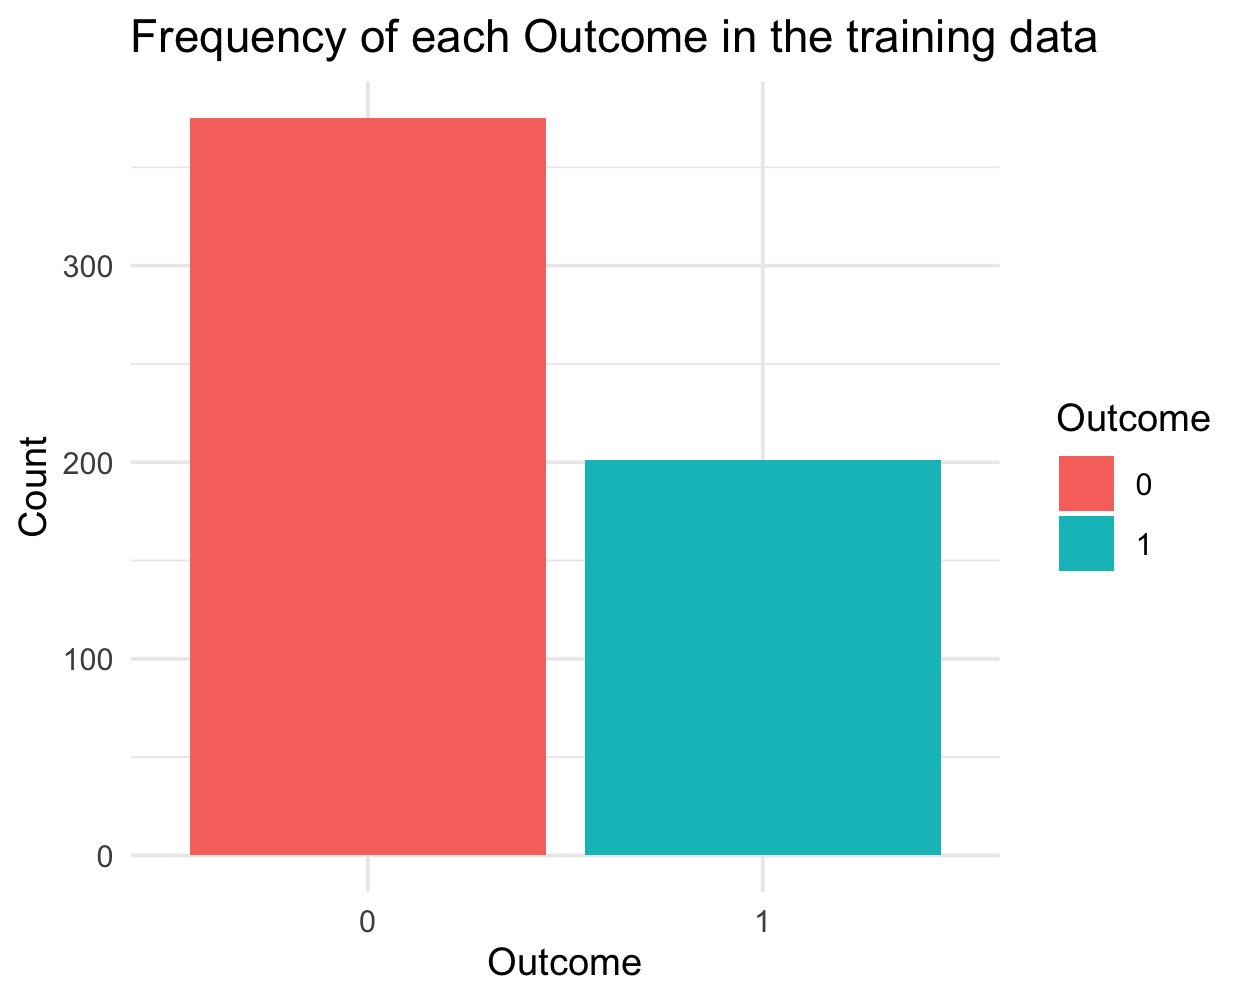

In [5]:
# Note: build the ggplot object first, then add layers with + (the standard ggplot2 way).
bar_counts <- diabetes_train |> count(Outcome)
ggplot(bar_counts, aes(x = Outcome, y = n, fill = Outcome)) +
  geom_col() +
  labs(x = "Outcome", y = "Count", title = "Frequency of each Outcome in the training data") +
  theme_minimal()

❓ Is the data balanced? I.e. do we have equal counts of each outcome?

**Answer:** No. The two outcomes are not equal — there are 375 non-diabetes (0) cases versus 
201 diabetes (1) cases in the training set (roughly 65% vs. 35%). The data is therefore unbalanced 
(imbalanced) toward the non-diabetes class.

In [6]:
diabetes_train |>
    count(Outcome) |>
    mutate(prop = n / sum(n))

Outcome,n,prop
<fct>,<int>,<dbl>
0,375,0.6510417
1,201,0.3489583


Run the code below to create a table for plotting the predictors we will use in our model: `Glucose` and `BMI`. 

In [7]:
plot_df = diabetes_train |>
    select(Outcome, Glucose, BMI) |>
    pivot_longer(cols = c(Glucose, BMI))

plot_df |> head()

Outcome,name,value
<fct>,<chr>,<dbl>
0,Glucose,89.0
0,BMI,28.1
0,Glucose,116.0
0,BMI,25.6
0,Glucose,115.0
0,BMI,35.3


Using `plot_df`, make a chart showing the relationship of `Glucose` and `BMI` with `Outcome`. 

- use `geom_jitter` for your "geom"
- `facet_wrap` your chart by the `name` variable. (e.g. `facet_wrap(~name, ncol = 2, scales = 'free_x')`)

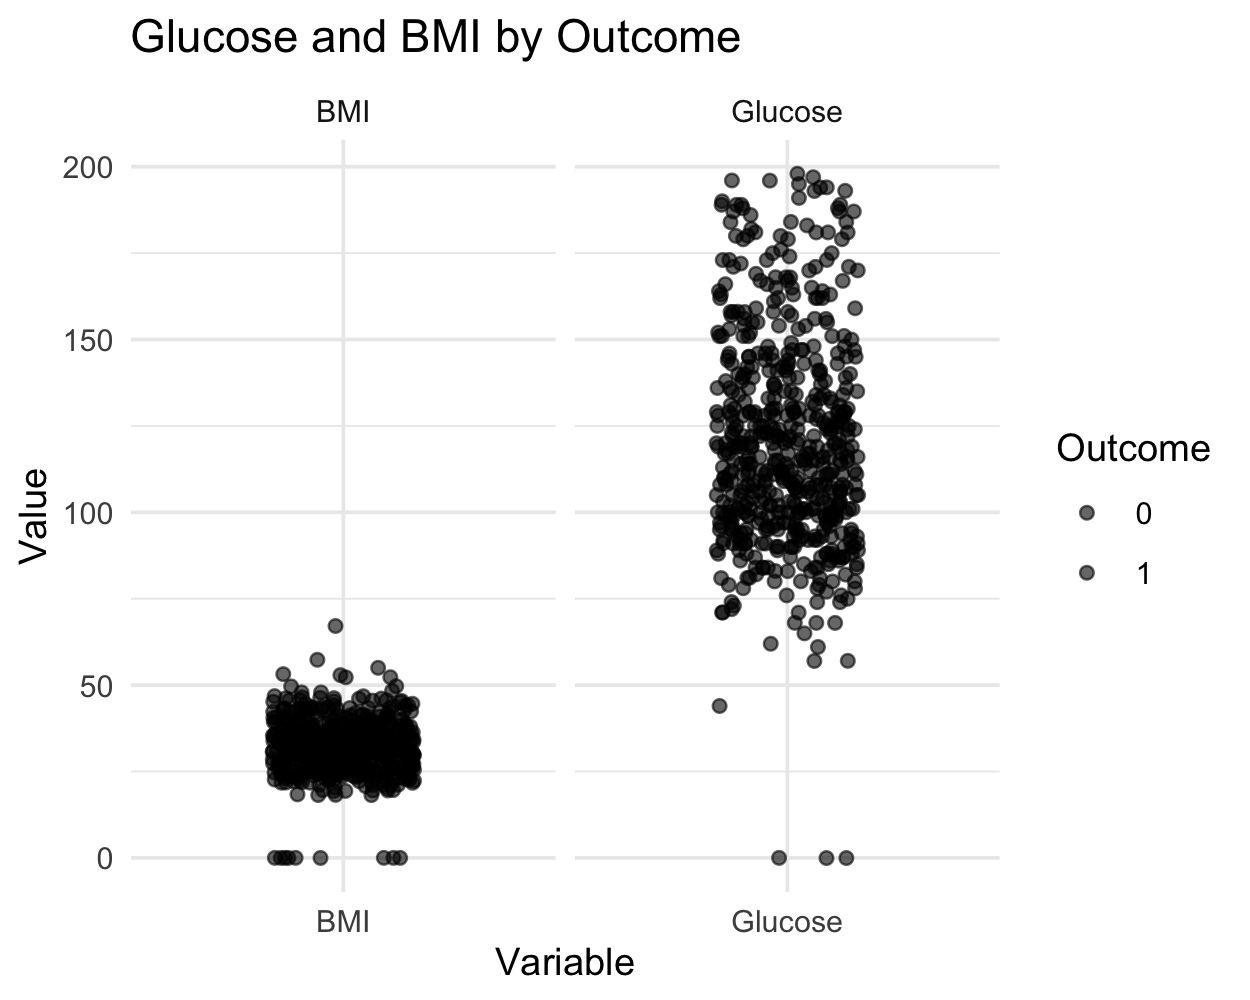

In [8]:
# Add layers with + (the standard ggplot2 way).
ggplot(plot_df, aes(x = name, y = value, fill = Outcome)) +
  geom_jitter(width = 0.2, alpha = 0.6) +
  facet_wrap(~name, ncol = 2, scales = "free_x") +
  labs(x = "Variable", y = "Value", title = "Glucose and BMI by Outcome") +
  theme_minimal()

❓ What happens when you remove the `scales = 'free_x'` argument from the `facet_wrap` function?

**Answer:** Both facets then share one common x-axis scale. Because the numeric ranges differ a lot 
(BMI is roughly 15–60 while Glucose is roughly 0–200), the BMI facet's points get compressed into a 
narrow band on the left side of the shared axis, making that facet much harder to read.

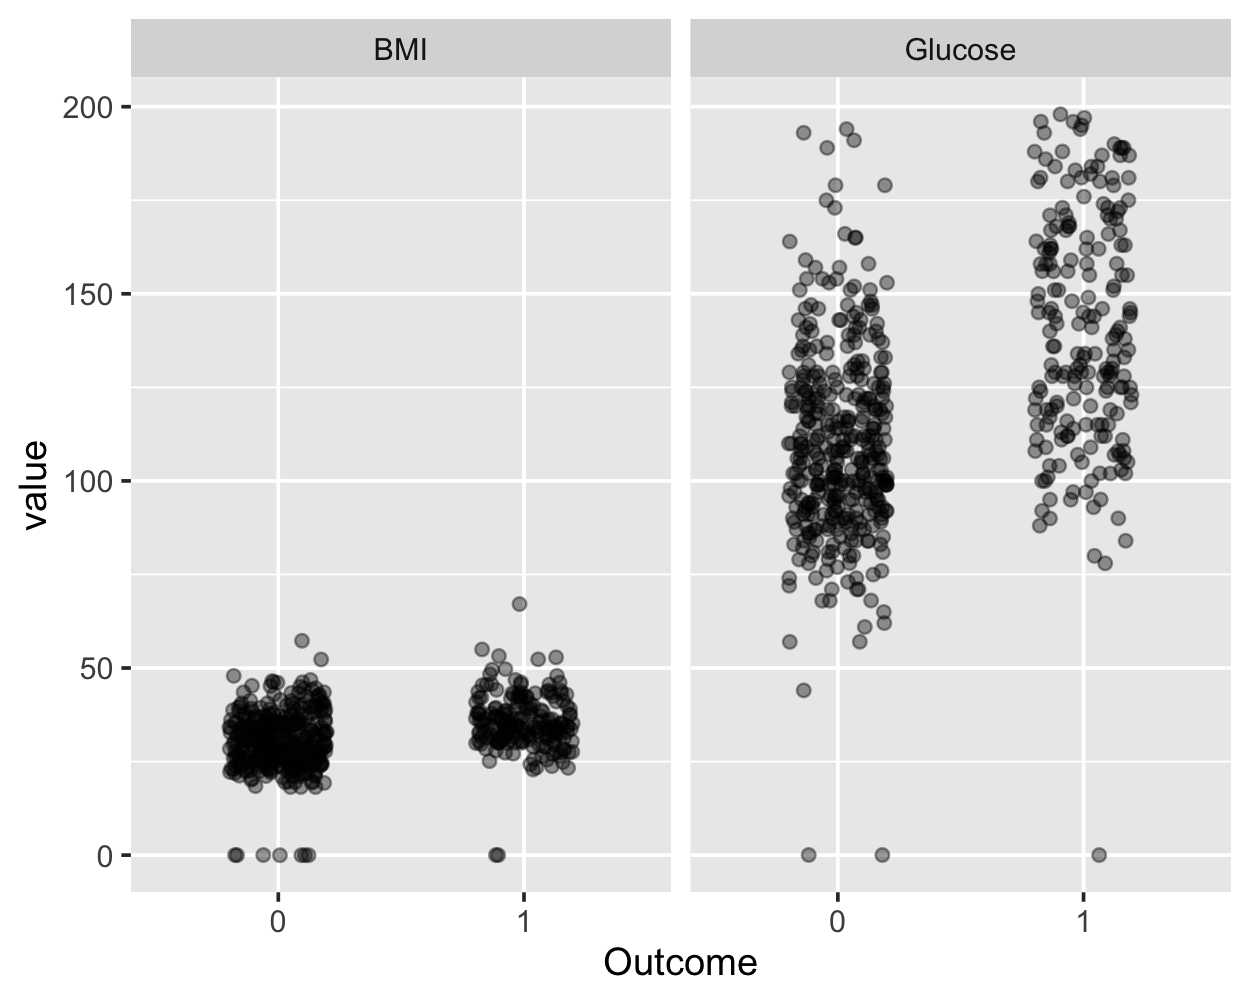

In [9]:
plot_df |>
    ggplot(aes(x = Outcome, y = value)) +
    geom_jitter(width = 0.2, alpha = 0.4) +
    facet_wrap(~name, ncol = 2)

Using your training data, build logistic regression model of `Outcome` with `BMI` and `Glucose` as predictors. 
- Use "glm" for you engine
- The formula for your fit function will be `Outcome ~ BMI + Glucose`

In [10]:
# Build a logistic regression (classification) model with BMI and Glucose as predictors.
mod_fit <-
  logistic_reg(engine = "glm") |>
  set_mode("classification") |>
  fit(Outcome ~ BMI + Glucose, data = diabetes_train)

Using `augment` with your fitted model and the `diabetes_test` data as arguments, create a new dataset called `diabetes_test_wPred` that is the `diabetes_test` table including predictions from your model. 

In [11]:
# Add the model's predictions to the test set to create diabetes_test_wPred.
diabetes_test_wPred <-
  augment(mod_fit, new_data = diabetes_test) |>
  mutate(.pred_class = factor(ifelse(.pred_1 >= 0.5, "1", "0"), levels = c("0", "1")))

diabetes_test_wPred

.pred_class,.pred_0,.pred_1,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
0,0.92132089,0.078679114,1,85,66,29,0,26.6,0.351,31,0
1,0.35870823,0.641291775,0,137,40,35,168,43.1,2.288,33,1
1,0.14916779,0.850832213,2,197,70,45,543,30.5,0.158,53,1
0,0.63115220,0.368847798,10,139,80,0,0,27.1,1.441,57,0
1,0.42326514,0.576734859,5,166,72,19,175,25.8,0.587,51,1
1,0.47058237,0.529417631,0,118,84,47,230,45.8,0.551,31,1
0,0.52133403,0.478665974,3,126,88,41,235,39.3,0.704,27,0
0,0.78885430,0.211145698,8,99,84,0,0,35.4,0.388,50,0
1,0.08342186,0.916578137,7,196,90,0,0,39.8,0.451,41,1


Run the code below to generate a confusion matrix for your model predictions. 

(❗️Hint: See Table 4.4 from [*Introduction to Statistical Learning (Version 2)*](https://www.statlearning.com/) for an example confusion matrix.)

In [12]:
diabetes_test_wPred = augment(mod_fit, new_data = diabetes_test)

diabetes_test_wPred |> conf_mat(Outcome, .pred_class)

          Truth
Prediction   0   1
         0 112  31
         1  13  36

❓ Based on the confusion matrix above,
- How many individuals had diabetes in your test data?
- Of those that actually had diabetes, how many were predicted to have diabetes by your model?
- How many individuals predicted to have diabetes did not have diabetes?

**Answer (assuming `set.seed(123)` in cell 3, so the train/test split matches):**

- **Had diabetes in the test data:** 67 individuals (the actual "1" count).
- **Of those, predicted to have diabetes:** 36 (true positives).
- **Predicted to have diabetes but did not actually have it:** 13 (false positives).

(Note: these numbers come from the split made with `set.seed(123)`. If you use a different seed, 
the exact counts will differ slightly, but you read them straight off your own confusion matrix.)